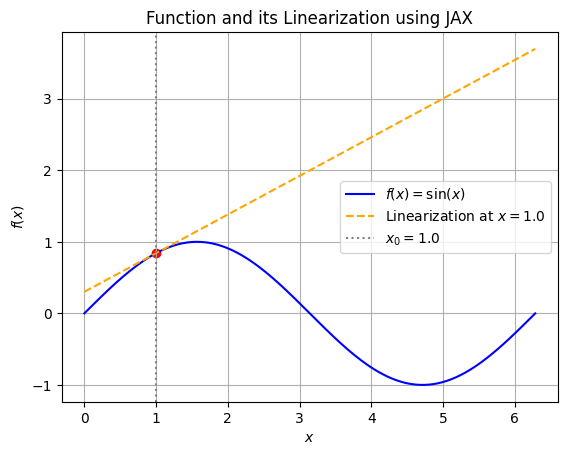

In [ ]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt


# Define a scalar function
def f(x):
    return jnp.sin(x)


# Point to linearize around
x0 = 1.0

# Use jax.linearize
f_x0, linear_fn = jax.linearize(f, x0)


# Linear approximation function for a single value
def f_linear_approx_single(x):
    delta_x = x - x0
    return f_x0 + linear_fn(delta_x)


# Vectorize it over an array of x values
f_linear_approx = jax.vmap(f_linear_approx_single)

# Values for plotting
x_vals = jnp.linspace(0.0, 2.0 * jnp.pi, 200)
f_vals = f(x_vals)
f_lin_vals = f_linear_approx(x_vals)

# Plotting
plt.plot(x_vals, f_vals, label=r"$f(x) = \sin(x)$", color="blue")
plt.plot(
    x_vals, f_lin_vals, "--", label="Linearization at $x=1.0$", color="orange"
)
plt.axvline(x=x0, color="gray", linestyle=":", label=r"$x_0=1.0$")
plt.scatter([x0], [f(x0)], color="red")
plt.legend()
plt.xlabel("$x$")
plt.ylabel("$f(x)$")
plt.title("Function and its Linearization using JAX")
plt.grid(True)
plt.show()


In [ ]:
from hcnn.constraint.constraint_state_outside_sphere import (
    ConstraintStateOutsideSphere,
)
from hcnn.policy.policy_lqr import PolicyLQR
from hcnn.system.system_linear import SystemLinear

state_matrix = jnp.array([[1, -1], [1, 0]])
input_matrix = jnp.array([[1.0], [0.0]])
system = SystemLinear.factory(
    state_matrix=state_matrix, input_matrix=input_matrix
)


state_cost = jnp.eye(2)
input_cost = jnp.eye(1)
policy = PolicyLQR.factory(system, state_cost, input_cost)


center = jnp.array([2.0, 2.0])
radius = 1
constraint = ConstraintStateOutsideSphere.factory(center=center, radius=radius)


TypeError: unsupported operand type(s) for *: 'SystemLinear' and 'int'